# 請求書やレシートの画像から、日付・金額・取引先・明細を JSON で取り出す

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/32_vision_language/document_field_extraction.ipynb)

NLP クックブック 32-06 ／ 画像と言語

> GPU ランタイム推奨（ランタイム → ランタイムのタイプを変更 → T4 GPU）

請求書やレシートの画像から、取引先・日付・明細・小計・消費税・合計を JSON で取り出して、会計のデータとして扱いたい。正解が分かるように PIL で書類の画像を作り、視覚言語モデル (VLM) に画像から直接 JSON を出させる方法と、OCR (Tesseract) で読んだテキストを LLM で JSON にする方法を、項目ごとの正解率で比べる。明細の合計と小計が合うかのような検算で、誤りをどこまで見つけられるかも確かめる。

In [1]:
# 所要時間の目安: T4 の Colab で 10〜15 分程度と見込む（モデルのダウンロード約 9GB を含む。T4 では未測定で、検証の GPU での時間の 2〜3 倍として見積もった）
# Tesseract 本体（Colab には入っている）と日本語のモデル、日本語フォント (Noto CJK)
!apt-get install -y -q tesseract-ocr tesseract-ocr-jpn fonts-noto-cjk > /dev/null
!pip install -q pytesseract

24 枚。正解の例: {'vendor': '青空ベーカリー', 'date': '2025-01-08', 'items': [{'name': '消しゴム', 'quantity': 3, 'unit_price': 140, 'amount': 420}, {'name': 'ノート B5', 'quantity': 1, 'unit_price': 250, 'amount': 250}, {'name': '食パン', 'quantity': 3, 'unit_price': 410, 'amount': 1230}, {'name': 'クロワッサン', 'quantity': 1, 'unit_price': 190, 'amount': 190}, {'name': 'ホットサンド', 'quantity': 1, 'unit_price': 740, 'amount': 740}], 'subtotal': 2830, 'tax': 283, 'total': 3113}


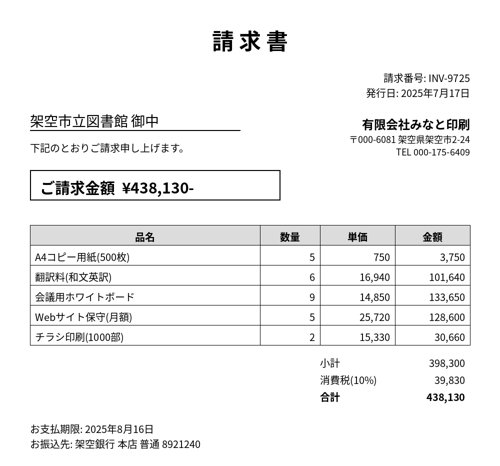

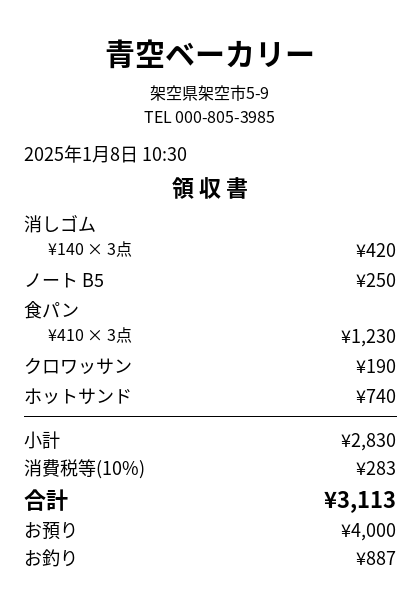

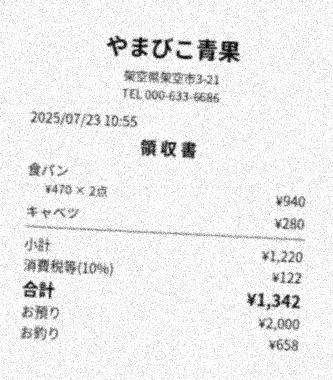

In [2]:
# 正解の分かる請求書とレシートの画像を PIL で作る（会社名・店名・住所・電話番号はすべて架空）
import random
from datetime import date, timedelta
import numpy as np
from PIL import Image, ImageDraw, ImageFilter, ImageFont

SANS = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
BOLD = "/usr/share/fonts/opentype/noto/NotoSansCJK-Bold.ttc"
font = lambda size, bold=False: ImageFont.truetype(BOLD if bold else SANS, size)

VENDORS = {"invoice": ["株式会社クックブック商事", "合同会社ことば工房", "有限会社みなと印刷", "株式会社さくらシステム"],
           "receipt": ["ひまわり文具店", "青空ベーカリー", "やまびこ青果", "喫茶こもれび"]}
CUSTOMERS = ["株式会社テスト物産", "架空市立図書館", "合同会社サンプル企画", "株式会社れい電機"]   # 請求書の宛先（取引先と紛らわしい）
GOODS = {"invoice": [("A4コピー用紙(500枚)", 450, 800), ("ボールペン(黒)10本", 600, 1200), ("名刺印刷(100枚)", 1500, 3500),
                     ("Webサイト保守(月額)", 20000, 50000), ("翻訳料(和文英訳)", 8000, 30000), ("チラシ印刷(1000部)", 9000, 18000),
                     ("ノートPCスタンド", 2500, 6000), ("会議用ホワイトボード", 12000, 25000), ("ソフトウェア利用料", 3000, 9000)],
         "receipt": [("食パン", 220, 480), ("クロワッサン", 160, 260), ("ブレンドコーヒー", 380, 520), ("りんご", 120, 250),
                     ("キャベツ", 150, 300), ("ノート B5", 150, 280), ("消しゴム", 80, 150), ("ホットサンド", 550, 780),
                     ("牛乳 1L", 200, 280), ("付箋", 180, 400)]}

def fmt_date(d, style):   # 日付の書き方を 3 通りにする
    if style == "漢字":
        return f"{d.year}年{d.month}月{d.day}日"
    if style == "スラッシュ":
        return f"{d.year}/{d.month:02d}/{d.day:02d}"
    return f"令和{d.year - 2018}年{d.month}月{d.day}日"          # 和暦: 令和元年 = 2019 年

def make_truth(rng, kind):
    d = date(2025, 1, 1) + timedelta(days=rng.randrange(365))
    items = []
    for name, lo, hi in rng.sample(GOODS[kind], rng.randint(2, 5)):
        qty, unit = rng.randint(1, 3 if kind == "receipt" else 10), rng.randrange(lo, hi, 10)
        items.append({"name": name, "quantity": qty, "unit_price": unit, "amount": qty * unit})
    subtotal = sum(it["amount"] for it in items)
    tax = subtotal // 10                                          # 消費税 10%（1 円未満は切り捨て）
    return {"vendor": rng.choice(VENDORS[kind]), "date": d.isoformat(), "items": items,
            "subtotal": subtotal, "tax": tax, "total": subtotal + tax}

def draw_invoice(t, rng, style):
    W = 1000
    img = Image.new("RGB", (W, 1300), "white"); d = ImageDraw.Draw(img)
    dd = date.fromisoformat(t["date"])
    d.text((W // 2, 60), "請 求 書", font=font(44, True), fill="black", anchor="mt")
    d.text((W - 60, 140), f"請求番号: INV-{rng.randint(1000, 9999)}", font=font(20), fill="black", anchor="ra")
    d.text((W - 60, 170), f"発行日: {fmt_date(dd, style)}", font=font(20), fill="black", anchor="ra")
    d.text((60, 220), f"{rng.choice(CUSTOMERS)} 御中", font=font(28), fill="black")
    d.line([(60, 260), (480, 260)], fill="black", width=2)
    d.text((60, 280), "下記のとおりご請求申し上げます。", font=font(20), fill="black")
    d.text((W - 60, 230), t["vendor"], font=font(24, True), fill="black", anchor="ra")
    d.text((W - 60, 265), f"〒000-{rng.randint(1000, 9999)} 架空県架空市{rng.randint(1, 9)}-{rng.randint(1, 30)}", font=font(18), fill="black", anchor="ra")
    d.text((W - 60, 290), f"TEL 000-{rng.randint(100, 999)}-{rng.randint(1000, 9999)}", font=font(18), fill="black", anchor="ra")
    d.rectangle([60, 340, 560, 400], outline="black", width=2)
    d.text((80, 352), f"ご請求金額  ¥{t['total']:,}-", font=font(30, True), fill="black")
    cols, y = [60, 520, 640, 790, W - 60], 450                    # 明細の表（品名・数量・単価・金額）
    d.rectangle([cols[0], y, cols[-1], y + 40], fill=(220, 220, 220), outline="black")
    for x0, x1, h in zip(cols, cols[1:], ["品名", "数量", "単価", "金額"]):
        d.text(((x0 + x1) // 2, y + 8), h, font=font(20, True), fill="black", anchor="ma")
    for it in t["items"]:
        y += 40
        d.rectangle([cols[0], y, cols[-1], y + 40], outline="black")
        d.text((cols[0] + 10, y + 8), it["name"], font=font(20), fill="black")
        for x1, v in zip(cols[2:], [f"{it['quantity']}", f"{it['unit_price']:,}", f"{it['amount']:,}"]):
            d.text((x1 - 10, y + 8), v, font=font(20), fill="black", anchor="ra")
    for x in cols:
        d.line([(x, 450), (x, y + 40)], fill="black")
    y += 60
    for label, v in [("小計", t["subtotal"]), ("消費税(10%)", t["tax"]), ("合計", t["total"])]:
        d.text((cols[2], y), label, font=font(20, label == "合計"), fill="black")
        d.text((cols[-1] - 10, y), f"{v:,}", font=font(20, label == "合計"), fill="black", anchor="ra")
        y += 34
    d.text((60, y + 30), f"お支払期限: {fmt_date(dd + timedelta(days=30), style)}", font=font(20), fill="black")   # 発行日と紛らわしい日付
    d.text((60, y + 60), f"お振込先: 架空銀行 本店 普通 {rng.randint(1000000, 9999999)}", font=font(20), fill="black")
    return img.crop((0, 0, W, y + 120))

def draw_receipt(t, rng, style):
    W = 420
    img = Image.new("RGB", (W, 540 + len(t["items"]) * 60), "white"); d = ImageDraw.Draw(img)
    y = 30
    d.text((W // 2, y), t["vendor"], font=font(30, True), fill="black", anchor="ma"); y += 50
    d.text((W // 2, y), f"架空県架空市{rng.randint(1, 9)}-{rng.randint(1, 30)}", font=font(16), fill="black", anchor="ma"); y += 24
    d.text((W // 2, y), f"TEL 000-{rng.randint(100, 999)}-{rng.randint(1000, 9999)}", font=font(16), fill="black", anchor="ma"); y += 36
    d.text((24, y), f"{fmt_date(date.fromisoformat(t['date']), style)} {rng.randint(9, 20)}:{rng.randint(0, 59):02d}", font=font(18), fill="black"); y += 30
    d.text((W // 2, y), "領 収 書", font=font(22, True), fill="black", anchor="ma"); y += 40
    for it in t["items"]:
        d.text((24, y), it["name"], font=font(18), fill="black")
        if it["quantity"] > 1:                                    # 2 点以上は「単価 × 数量」の行を足す
            y += 26
            d.text((48, y), f"¥{it['unit_price']:,} × {it['quantity']}点", font=font(16), fill="black")
        d.text((W - 24, y), f"¥{it['amount']:,}", font=font(18), fill="black", anchor="ra"); y += 30
    d.line([(24, y + 4), (W - 24, y + 4)], fill="black"); y += 14
    paid = (t["total"] // 1000 + 1) * 1000
    for label, v, big in [("小計", t["subtotal"], False), ("消費税等(10%)", t["tax"], False), ("合計", t["total"], True),
                          ("お預り", paid, False), ("お釣り", paid - t["total"], False)]:   # お預り・お釣りは合計と紛らわしい金額
        d.text((24, y), label, font=font(22 if big else 18, big), fill="black")
        d.text((W - 24, y), f"¥{v:,}", font=font(22 if big else 18, big), fill="black", anchor="ra"); y += 34 if big else 28
    return img.crop((0, 0, W, y + 30))

def degrade(img, rng):
    """スマートフォンで撮ったレシートを模す: 縮小、傾き、ぼけ、ノイズ"""
    img = img.convert("L").resize((int(img.width * 0.75), int(img.height * 0.75)), Image.BILINEAR)
    img = img.rotate(rng.uniform(-4, 4), expand=True, fillcolor=255, resample=Image.BICUBIC)
    a = np.asarray(img.filter(ImageFilter.GaussianBlur(0.8)), dtype=float)
    a += np.random.default_rng(rng.randrange(10**6)).normal(0, 20, a.shape)
    return Image.fromarray(a.clip(0, 255).astype("uint8")).convert("RGB")

rng = random.Random(0)
docs = []
for kind in ["invoice", "receipt"]:
    for i in range(12):
        t = make_truth(rng, kind)
        style = ["漢字", "スラッシュ", "令和"][i % 3]
        img = draw_invoice(t, rng, style) if kind == "invoice" else draw_receipt(t, rng, style)
        group = "請求書"
        if kind == "receipt":
            group = "レシート (劣化)" if i % 2 else "レシート"
            if i % 2:
                img = degrade(img, rng)
        docs.append({"kind": kind, "group": group, "style": style, "truth": t, "image": img})
print(len(docs), "枚。正解の例:", docs[12]["truth"])
display(docs[0]["image"].resize((500, docs[0]["image"].height // 2)), docs[12]["image"], docs[13]["image"])

In [3]:
# VLM: Qwen3-VL-4B-Instruct (Apache-2.0)。画像なしでテキストだけを渡せば LLM としても使えるので、両方の方法で同じモデルを使う
# 初回はモデル（約 9GB）のダウンロードに数分かかる
import time
import torch
from transformers import AutoModelForImageTextToText, AutoProcessor

name = "Qwen/Qwen3-VL-4B-Instruct"
BF16 = torch.cuda.get_device_capability()[0] >= 8      # bfloat16 は Ampere (A100, L4) 以降。T4 では float16 を使う
processor = AutoProcessor.from_pretrained(name)
processor.tokenizer.padding_side = "left"              # 生成のバッチ処理では左パディング
model = AutoModelForImageTextToText.from_pretrained(name, dtype=torch.bfloat16 if BF16 else torch.float16, device_map="cuda").eval()

# 出力の形式は例で示す。日付は「書かれたとおり」と「YYYY-MM-DD に直したもの」の両方を出させ、あとで比べる
PROMPT = """{source}から、次の項目を取り出して JSON で出力してください。
- vendor: 書類を発行した会社または店の名前 (宛先ではない)
- date_text: 発行日 (書類に書かれたとおり)
- date: 発行日を YYYY-MM-DD の形式に直したもの
- items: 明細の配列。各要素は name (品名), quantity (数量), unit_price (単価), amount (金額)
- subtotal: 小計, tax: 消費税, total: 合計
金額は円の整数で書いてください。次の形式の JSON だけを出力してください。
{{"vendor": "...", "date_text": "...", "date": "YYYY-MM-DD", "items": [{{"name": "...", "quantity": 1, "unit_price": 100, "amount": 100}}], "subtotal": 100, "tax": 10, "total": 110}}"""

def generate(conversations, max_new_tokens=600, batch_size=8):
    """会話（メッセージのリスト）の一覧をバッチでまとめて生成する"""
    outs = []
    for i in range(0, len(conversations), batch_size):
        inputs = processor.apply_chat_template(conversations[i:i + batch_size], add_generation_prompt=True, tokenize=True,
                                               return_dict=True, return_tensors="pt", processor_kwargs={"padding": True}).to(model.device)
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        outs += [s.strip() for s in processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)]
    return outs

def ask_image(doc):    # (A) 画像から直接
    return [{"role": "user", "content": [{"type": "image", "image": doc["image"]}, {"type": "text", "text": PROMPT.format(source="この画像の書類")}]}]

# (A) VLM に画像から直接 JSON を出させる（T4 では 3 分前後かかる見込み）
torch.cuda.reset_peak_memory_stats(); t = time.perf_counter()
raw = {"VLM (画像→JSON)": generate([ask_image(d) for d in docs])}
print(f"{time.perf_counter() - t:.0f} 秒, 最大メモリ {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
print(raw["VLM (画像→JSON)"][12])

60 秒, 最大メモリ 11.4 GB
{
  "vendor": "青空ベーカリー",
  "date_text": "2025年1月8日 10:30",
  "date": "2025-01-08",
  "items": [
    {
      "name": "消しゴム",
      "quantity": 3,
      "unit_price": 140,
      "amount": 420
    },
    {
      "name": "ノート B5",
      "quantity": 1,
      "unit_price": 250,
      "amount": 250
    },
    {
      "name": "食パン",
      "quantity": 3,
      "unit_price": 410,
      "amount": 1230
    },
    {
      "name": "クロワッサン",
      "quantity": 1,
      "unit_price": 190,
      "amount": 190
    },
    {
      "name": "ホットサンド",
      "quantity": 1,
      "unit_price": 740,
      "amount": 740
    }
  ],
  "subtotal": 2830,
  "tax": 283,
  "total": 3113
}


In [4]:
# (B) OCR してから LLM で JSON にする。まず Tesseract で読む
import pytesseract

# レイアウトの指定 (--psm) で、表の読み方が変わる。psm 6 は全体を 1 つの文字のブロックとみなし、psm 4 は大きさの違う行が並ぶ 1 列とみなす
for psm in [6, 4]:
    print(f"--- psm {psm}\n" + pytesseract.image_to_string(docs[0]["image"], lang="jpn", config=f"--psm {psm}")[150:520])

t = time.perf_counter()
ocr_texts = [pytesseract.image_to_string(d["image"], lang="jpn", config="--psm 4") for d in docs]
print(f"OCR: 1 枚あたり {(time.perf_counter() - t) / len(docs):.2f} 秒 (CPU)")
print(ocr_texts[13])   # 劣化させたレシート

--- psm 6
000-6081 避空県架空市2-24
下記のとおりご請求申し上げます。                  『    人
ご請求金額 \438,130-
A4コピー用紙500失
和料人玉          | 6| ie| oueel
| 全業ホワイトポード。。 | 9| nessol| iaaesol
Webサイト保き件
チラシ印肌000剖
小計                          398,300
消費税(1096)                 39,830
合計                         438,130
お支払期限: 2025年8月16日
お振込先: 架空銀行 本店 普通 8921240

--- psm 4
            〒000-6081 架空県架空市2-24
下記のとおりご請求申し上げます。                                 TEL 000-175-6409

ご請求金額 \438,130-

品名                                          数量                単価                   金額
A4コピー用紙(500枚)                                                    5                 750               3.750
翻訳料(和文英訳)                                                   
OCR: 1 枚あたり 0.32 秒 (CPU)
やまびこ青果

家斉
TEL 09G 633-65mc

202570723 10.55
叙収書

食パン
W479x 2吉

キャペッ

小計
消区下部(109%)
合計

お預り
お勧り



In [5]:
# OCR のテキストを同じモデルに（画像なしで）渡して JSON にする（T4 では 1〜2 分かかる見込み）
def ask_text(text):    # (B) OCR のテキストから
    return [{"role": "user", "content": [{"type": "text", "text": PROMPT.format(source="次の OCR のテキスト (書類の画像から読み取ったもの) ") + "\n\nOCR のテキスト:\n" + text}]}]

t = time.perf_counter()
raw["OCR→LLM"] = generate([ask_text(s) for s in ocr_texts])
print(f"{time.perf_counter() - t:.0f} 秒")
print(raw["OCR→LLM"][12])

82 秒
{
  "vendor": "青空ベーカリー",
  "date_text": "2025年1月8日",
  "date": "2025-01-08",
  "items": [
    {
      "name": "消しゴム",
      "quantity": 3,
      "unit_price": 140,
      "amount": 420
    },
    {
      "name": "ノート B5",
      "quantity": 1,
      "unit_price": 250,
      "amount": 250
    },
    {
      "name": "食パン",
      "quantity": 3,
      "unit_price": 410,
      "amount": 1230
    },
    {
      "name": "クロワッサン",
      "quantity": 1,
      "unit_price": 190,
      "amount": 190
    },
    {
      "name": "ホットサンド",
      "quantity": 1,
      "unit_price": 740,
      "amount": 740
    }
  ],
  "subtotal": 2830,
  "tax": 283,
  "total": 3113
}


In [6]:
# 出力を JSON として取り出し、スキーマで検証してから、項目ごとに正解と比べる
# extract_json は大規模言語モデルの章の「LLM の出力から JSON を取り出して検証する」と同じもの
import json, re, unicodedata
import pandas as pd
from pydantic import BaseModel, ValidationError

class Item(BaseModel):
    name: str
    quantity: int
    unit_price: int
    amount: int

class Receipt(BaseModel):
    vendor: str
    date_text: str
    date: str
    items: list[Item]
    subtotal: int
    tax: int
    total: int

def extract_json(text):
    text = re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip(), flags=re.MULTILINE)
    start = text.find("{")
    if start < 0:
        raise ValueError("JSON が見つかりません")
    obj, _ = json.JSONDecoder().raw_decode(text[start:])
    return obj

def parse(out, schema=Receipt):
    try:
        return schema.model_validate(extract_json(out)).model_dump()
    except (ValueError, ValidationError):
        return None

def to_iso(s):
    """書かれたとおりの日付（2025年3月4日、2025/03/04、令和7年3月4日）を、和暦の変換も含めてコードで YYYY-MM-DD に直す。
    令和か 4 桁の西暦のときだけ受け付け、それ以外（OCR が「令和」を「信和」と読んだものなど）やありえない日付は None"""
    m = re.search(r"(?:令和\s*(\d+|元)|(\d{4}))\s*[年/.-]\s*(\d{1,2})\s*[月/.-]\s*(\d{1,2})", unicodedata.normalize("NFKC", s))
    if not m:
        return None
    year = int(m[2]) if m[2] else 2018 + (1 if m[1] == "元" else int(m[1]))   # 令和元年 = 2019 年
    try:
        return date(year, int(m[3]), int(m[4])).isoformat()
    except ValueError:
        return None

norm = lambda s: re.sub(r"\s", "", unicodedata.normalize("NFKC", s))   # 全角半角と空白の違いは許す
FIELDS = ["取引先", "日付 (モデルが変換)", "日付 (コードで変換)", "小計", "消費税", "合計", "明細 (すべての行)", "書類全体"]

def score(p, t):
    if p is None:                                  # JSON として読めない・スキーマに合わない
        return dict.fromkeys(FIELDS, False) | {"明細の行": 0.0}
    key = lambda it: (norm(it["name"]), it["quantity"], it["unit_price"], it["amount"])
    pred, gold = sorted(map(key, p["items"])), sorted(map(key, t["items"]))
    s = {"取引先": norm(p["vendor"]) == norm(t["vendor"]), "日付 (モデルが変換)": p["date"] == t["date"],
         "日付 (コードで変換)": to_iso(p["date_text"]) == t["date"],
         "小計": p["subtotal"] == t["subtotal"], "消費税": p["tax"] == t["tax"], "合計": p["total"] == t["total"],
         "明細 (すべての行)": pred == gold, "明細の行": sum(g in pred for g in gold) / len(gold)}   # 正解の行のうち、完全に一致した行の割合
    s["書類全体"] = all(s[k] for k in FIELDS[:-1] if k != "日付 (モデルが変換)")
    return s

parsed = {m: [parse(o) for o in outs] for m, outs in raw.items()}
rows = [{"方法": m, "書類": d["group"], "日付の書き方": d["style"], **score(p, d["truth"])}
        for m, ps in parsed.items() for p, d in zip(ps, docs)]
df = pd.DataFrame(rows)
print("JSON として読めなかった数:", {m: sum(p is None for p in ps) for m, ps in parsed.items()})
cols = FIELDS[:-1] + ["明細の行", "書類全体"]
print(df.groupby("方法", sort=False)[cols].mean().round(2).T.to_string())
print("\n書類の種類ごとの「書類全体」の正解率\n" + df.pivot_table(index="書類", columns="方法", values="書類全体", sort=False).round(2).to_string())
print("\n日付の書き方ごとの正解率 (モデルが変換 / コードで変換)\n" +
      df.groupby(["方法", "日付の書き方"], sort=False)[["日付 (モデルが変換)", "日付 (コードで変換)"]].mean().round(2).to_string())
print("\n日付がどちらかで誤った書類 (書かれたとおりの日付 → コードの変換 / モデルの変換 / 正解)")
for m, ps in parsed.items():
    for i, (p, d) in enumerate(zip(ps, docs)):
        if p is not None and (to_iso(p["date_text"]) != d["truth"]["date"] or p["date"] != d["truth"]["date"]):
            print(f"  {m} #{i} {d['style']}: 「{p['date_text']}」→ {to_iso(p['date_text'])} / {p['date']} / {d['truth']['date']}")

JSON として読めなかった数: {'VLM (画像→JSON)': 0, 'OCR→LLM': 0}
方法           VLM (画像→JSON)  OCR→LLM
取引先                   1.00     0.88
日付 (モデルが変換)           1.00     0.83
日付 (コードで変換)           1.00     0.75
小計                    0.96     0.75
消費税                   1.00     0.75
合計                    0.96     0.75
明細 (すべての行)            0.83     0.62
明細の行                  0.92     0.71
書類全体                  0.83     0.54

書類の種類ごとの「書類全体」の正解率
方法         VLM (画像→JSON)  OCR→LLM
書類                               
請求書                 1.00     0.67
レシート                1.00     0.83
レシート (劣化)           0.33     0.00

日付の書き方ごとの正解率 (モデルが変換 / コードで変換)
                      日付 (モデルが変換)  日付 (コードで変換)
方法            日付の書き方                          
VLM (画像→JSON) 漢字             1.00         1.00
              スラッシュ          1.00         1.00
              令和             1.00         1.00
OCR→LLM       漢字             0.88         0.88
              スラッシュ          0.88         0.75
              令和             0.75    

In [7]:
# 比較: 書かれたとおりの日付 (date_text) を出させずに、いきなり YYYY-MM-DD を出させる（令和で書いた 8 枚。T4 では 1 分前後かかる見込み）
class ReceiptNoDateText(Receipt):
    date_text: str = ""                      # このプロンプトでは出させないので、なくてもよいことにする

PROMPT_NO_TEXT = PROMPT.replace("- date_text: 発行日 (書類に書かれたとおり)\n", "").replace(' "date_text": "...",', "")
assert "date_text" not in PROMPT_NO_TEXT
reiwa = [i for i, d in enumerate(docs) if d["style"] == "令和"]
outs = generate([[{"role": "user", "content": [{"type": "image", "image": docs[i]["image"]},
                                               {"type": "text", "text": PROMPT_NO_TEXT.format(source="この画像の書類")}]}] for i in reiwa])
get_date = lambda p: p["date"] if p else "(読めない)"
for i, o in zip(reiwa, outs):
    print(f"#{i} {docs[i]['group']}: 正解 {docs[i]['truth']['date']} → date_text なし {get_date(parse(o, ReceiptNoDateText))}"
          f" / あり {get_date(parsed['VLM (画像→JSON)'][i])}")

#2 請求書: 正解 2025-12-30 → date_text なし 2025-12-30 / あり 2025-12-30
#5 請求書: 正解 2025-08-19 → date_text なし 2025-08-19 / あり 2025-08-19
#8 請求書: 正解 2025-01-21 → date_text なし 2025-01-21 / あり 2025-01-21
#11 請求書: 正解 2025-07-25 → date_text なし 2025-07-25 / あり 2025-07-25
#14 レシート: 正解 2025-01-10 → date_text なし 2023-01-10 / あり 2025-01-10
#17 レシート (劣化): 正解 2025-02-25 → date_text なし 2023-02-25 / あり 2025-02-25
#20 レシート: 正解 2025-03-02 → date_text なし 2023-03-02 / あり 2025-03-02
#23 レシート (劣化): 正解 2025-03-24 → date_text なし 2023-03-24 / あり 2025-03-24


In [8]:
# 検算: 数量×単価=金額、数量・金額が正、明細の合計=小計、小計の 10% = 消費税（端数の扱いの違いで ±1 円は許す）、小計+消費税=合計、
# 日付をコードで読めるか（令和か 4 桁の西暦か）、年が 2000 年から今年までか
def check(p):
    if p is None:
        return ["JSON として読めない"]
    errors = [f"「{it['name']}」の数量×単価 ({it['quantity']}×{it['unit_price']}) が金額 {it['amount']} と合わない"
              for it in p["items"] if it["quantity"] * it["unit_price"] != it["amount"]]
    if not p["items"] or any(it["quantity"] <= 0 or it["amount"] <= 0 for it in p["items"]):
        errors.append("明細がない、または数量・金額が 0 以下の行がある")
    if sum(it["amount"] for it in p["items"]) != p["subtotal"]:
        errors.append(f"明細の金額の合計 {sum(it['amount'] for it in p['items'])} が小計 {p['subtotal']} と合わない")
    if abs(p["subtotal"] * 0.1 - p["tax"]) > 1:
        errors.append(f"消費税 {p['tax']} が小計 {p['subtotal']} の 10% と合わない")
    if p["subtotal"] + p["tax"] != p["total"]:
        errors.append(f"小計+消費税 ({p['subtotal']}+{p['tax']}) が合計 {p['total']} と合わない")
    iso = to_iso(p["date_text"])
    if iso is None:
        errors.append(f"日付「{p['date_text']}」を読めない")
    elif not 2000 <= int(iso[:4]) <= date.today().year:
        errors.append(f"日付「{p['date_text']}」の年がありえない")
    return errors

df["検算"] = ["NG" if check(p) else "OK" for ps in parsed.values() for p in ps]
df["正誤"] = df["書類全体"].map({True: "全項目正しい", False: "誤りあり"})
print(pd.crosstab([df["方法"], df["検算"]], df["正誤"]).to_string())

# 検算を通ったのに誤りがあった書類: 何を間違えたか
for m, ps in parsed.items():
    for i, (p, d) in enumerate(zip(ps, docs)):
        s = score(p, d["truth"])
        if p is not None and not check(p) and not s["書類全体"]:
            wrong = [k for k in FIELDS[:-1] if k != "日付 (モデルが変換)" and not s[k]]
            print(f"{m} #{i} {d['group']}: {', '.join(wrong)} | 出力 {p['vendor']} {p['date_text']} "
                  f"{[(it['name'], it['quantity'], it['unit_price'], it['amount']) for it in p['items']]}")

正誤                全項目正しい  誤りあり
方法            検算              
OCR→LLM       NG       0     9
              OK      13     2
VLM (画像→JSON) NG       0     3
              OK      20     1
VLM (画像→JSON) #19 レシート (劣化): 明細 (すべての行) | 出力 やまびこ青果 2025/09/08 17:28 [('満しゴム', 1, 100, 100), ('クロワッサン', 3, 180, 540), ('ノート B5', 2, 180, 360)]
OCR→LLM #3 請求書: 取引先 | 出力 株式会社テスト物産 2025年9月8日 [('翻訳料(和文英訳)', 2, 21620, 43240), ('ソフトウェア利用料', 9, 5080, 45720)]
OCR→LLM #6 請求書: 明細 (すべての行) | 出力 有限会社みなと印刷 2025年1月24日 [('A4コピー用紙(500枚)', 4, 520, 2080), ('ボールペン(上黒)10本', 7, 650, 4550)]


In [9]:
# 検算で不整合が見つかった書類だけ、どこが合わないかを伝えて読み直させる（T4 では 1〜2 分かかる見込み）
def show(q):   # 明細の（数量, 単価, 金額）と、小計・消費税・合計
    return [(it["quantity"], it["unit_price"], it["amount"]) for it in q["items"]] + [q["subtotal"], q["tax"], q["total"]]

retry = {}
for m, ps in parsed.items():
    idx = [i for i, p in enumerate(ps) if check(p)]
    first = [ask_image(docs[i]) if m.startswith("VLM") else ask_text(ocr_texts[i]) for i in idx]
    convs = [c + [{"role": "assistant", "content": raw[m][i]},
                  {"role": "user", "content": "検算で次の不整合が見つかりました。\n" + "\n".join(check(parsed[m][i])) +
                   "\n書類に書かれている数字をもう一度確かめて、JSON だけを出力し直してください。"}] for c, i in zip(first, idx)]
    retry[m] = dict(zip(idx, map(parse, generate(convs))))
    for i, p in retry[m].items():
        before, after = score(parsed[m][i], docs[i]["truth"]), score(p, docs[i]["truth"])
        print(f"{m} #{i} {docs[i]['group']}: 検算 {'OK' if not check(p) else 'NG'}, "
              f"書類全体 {before['書類全体']} → {after['書類全体']}, 明細の行 {before['明細の行']:.2f} → {after['明細の行']:.2f}")
        if m.startswith("VLM") and p is not None:   # 何が変わったか（正解、1 回目、読み直し後の明細）
            print(f"    正解 {show(docs[i]['truth'])}\n    1 回目 {show(parsed[m][i])}\n    読み直し {show(p)}")

# 読み直したあとの、検算の結果と正誤の対応
df["検算 (読み直し後)"] = ["NG" if check(retry[m].get(i, p)) else "OK" for m, ps in parsed.items() for i, p in enumerate(ps)]
df["正誤 (読み直し後)"] = [("全項目正しい" if score(retry[m].get(i, p), d["truth"])["書類全体"] else "誤りあり")
                         for m, ps in parsed.items() for i, (p, d) in enumerate(zip(ps, docs))]
print(pd.crosstab([df["方法"], df["検算 (読み直し後)"]], df["正誤 (読み直し後)"]).to_string())

VLM (画像→JSON) #13 レシート (劣化): 検算 OK, 書類全体 False → True, 明細の行 0.50 → 1.00
    正解 [(2, 470, 940), (1, 280, 280), 1220, 122, 1342]
    1 回目 [(2, 940, 940), (1, 280, 280), 1220, 122, 1342]
    読み直し [(2, 470, 940), (1, 280, 280), 1220, 122, 1342]
VLM (画像→JSON) #15 レシート (劣化): 検算 OK, 書類全体 False → False, 明細の行 0.80 → 0.80
    正解 [(3, 190, 570), (1, 220, 220), (1, 420, 420), (2, 210, 420), (2, 230, 460), 2090, 209, 2299]
    1 回目 [(3, 170, 510), (1, 220, 220), (1, 420, 420), (2, 210, 420), (2, 230, 460), 2030, 209, 2239]
    読み直し [(3, 170, 510), (1, 220, 220), (1, 420, 420), (2, 210, 420), (2, 230, 460), 2030, 203, 2233]
VLM (画像→JSON) #21 レシート (劣化): 検算 NG, 書類全体 False → False, 明細の行 0.20 → 0.20
    正解 [(1, 230, 230), (3, 620, 1860), (1, 250, 250), (3, 280, 840), (2, 80, 160), 3340, 334, 3674]
    1 回目 [(1, 230, 230), (3, 1860, 1860), (1, 250, 250), (3, 840, 840), (2, 160, 160), 3340, 334, 3674]
    読み直し [(1, 230, 230), (3, 1860, 5580), (1, 250, 250), (3, 840, 2520), (2, 160, 320), 9000, 900, 9900]


- 数値はすべて float16（`BF16 = False`、T4 と同じ dtype）で実行したもの。書類は 24 枚（請求書 12、レシート 12 のうち 6 枚は縮小・傾き・ぼけ・ノイズで劣化させたもの）で、1 枚で正解率が 0.04（劣化させたレシート 6 枚だけの正解率では 0.17）動く。1 種類のフォントで描いた架空の書式の合成画像なので、手書き、かすれた感熱紙、多様なレイアウト、軽減税率 (8%) の混在や内税は試していない。対象と同じ種類の書類に正解を付けて、同じ方法で測ってから使う。
- 書類全体（日付はコードで変換したもの）がすべて正しかった割合は、VLM に画像から直接出させると 0.83、OCR→LLM では 0.54 だった（明細の行の一致率は 0.92 と 0.71、合計は 0.96 と 0.75）。同じモデルを使っているので、差は入力（画像か OCR のテキストか）の違いによる。Tesseract は `--psm 6` だと表の数値を「ie| oueel」のように崩し、`--psm 4` では行ごとに読めた。劣化させたレシートは、上の例のように「小計」「合計」のラベルだけが残って数字が読めないことがあり、OCR→LLM は 6 枚とも誤った。ほかに、請求書の宛先（株式会社テスト物産）を取引先と答えた。VLM も劣化させたレシートでは 6 枚中 2 枚しか全項目が正しくなく、「¥470 × 2点 ¥940」の単価に金額の 940 を入れる、ぼけた 190 を 170 と読む、「消しゴム」を「満しゴム」と読む誤りがあった。
- 日付は、書かれたとおりの文字列 (`date_text`) と YYYY-MM-DD の両方を出させた。`date_text` を出させずに YYYY-MM-DD だけを出させると、この例では、令和で書いたレシート 4 枚はすべて年を 2023 年とした（請求書の 4 枚は正しかった）。`date_text` も出させると 8 枚とも正しかった。8 枚での比較なので傾向の目安だが、書かれたとおりの値を残しておけば、和暦の変換のような決まった処理はコード (`to_iso`) で行い、モデルの変換と照合できる。`to_iso` は令和か 4 桁の西暦だけを受け付けるので、OCR→LLM で OCR が「令和」を「信和」と読んだ 2 枚（#2、#17）と、日付の区切りが消えて「202570723」となった 1 枚 (#13) では変換できなかった。モデルは #17 と #13 を推測で正しく直したので、OCR→LLM の日付の正解率はモデルの変換 0.83 に対してコードの変換 0.75 だった（#2 はモデルも 2024 年と誤った）。推測で直した値は確かめようがないので、変換できない書類は人が見るほうが安全である。
- 検算（数量×単価=金額、数量・金額が正、明細の合計=小計、消費税=小計の 10%、小計+消費税=合計、日付をコードで読めて年が 2000 年から今年まで）で NG になった書類は、VLM の 3 枚、OCR→LLM の 9 枚とも実際に誤りがあった（「信和」の 2 枚は日付の確認で NG になった）。一方、検算を通っても誤りのある書類が VLM で 1 枚（「満しゴム」）、OCR→LLM で 2 枚（宛先を取引先とした #3、品名を「ボールペン（上黒）」とした #6）あった。品名・取引先の誤りは検算では分からず、日付も形式と年の範囲しか見ないので、日の誤読（OCR→LLM の #23 は 3 月 24 日を 3 月 4 日とした）は通る。読み落とした行の数字どうしがたまたま合う場合も通る。検算は「NG なら確実に人が見る」ための仕組みで、「OK なら正しい」とは言えない。消費税の端数の扱い（切り捨て・四捨五入）は事業者で違うので ±1 円を許した。
- 検算で NG になった書類に、合わない箇所を伝えて読み直させると、VLM は 3 枚中 1 枚（単価に金額を入れていたもの）が直った。残りの 2 枚では、誤読した単価 170 をそのままにして正しかった消費税 209 を 203 に書き換えて検算を合わせたり、金額を数量倍して書類にない合計 9900 を作ったりした。OCR→LLM は 9 枚とも直らず、3 枚が検算に合う数字に書き換えて通ったので、検算を通るのに誤りがある書類が 2 枚から 5 枚に増えた（VLM でも 1 枚から 2 枚に増えた）。テキストにない数字は読み直しても取り戻せず、検算に合う数字を作ってしまう。読み直しは試してよいが、検算を通ったことを正しさの根拠にせず、NG の書類は人が確かめる流れにする。
- ここでは出力の形式を例で示し、`extract_json` と pydantic で検証した（大規模言語モデルの章の「LLM の出力から JSON を取り出して検証する」）。最初の 48 回の出力で JSON として読めなかったものはなかったが、形式を保証したいなら制約付きデコードや API の構造化出力を使う（LLM の API の章の「Gemini に決まった形式（JSON スキーマ）で出力させる」「Claude に決まった形式（JSON スキーマ）で出力させる」）。形式が保証されても、中の値が正しいとは限らないのは上のとおりである。実際の請求書やレシートには取引先や個人の情報が含まれるので、外部の API に送るかどうかは扱いの規程を確かめる（この手元のモデルなら外に出ない）。
- 時間とメモリ（検証の GPU で float16 で実行した値。T4 では測っていない）: VLM で 24 枚を 8 枚ずつのバッチで処理するのに 60 秒、OCR のテキストからの JSON 化に 82 秒（共有の GPU なので実行ごとに、前者は 53〜88 秒、後者は 38〜82 秒と変わった）。T4 ではこの 2〜3 倍かかると見込む。GPU メモリの最大使用量は 11.4GB（`torch.cuda.max_memory_allocated` の値で、CUDA の管理領域などは含まない）なので、T4 (16GB) に収まる見込みである。Tesseract は 1 枚 0.32 秒（検証の CPU での値。Colab の CPU ではこれより遅くなりうる）。Qwen3-VL-4B-Instruct は Apache-2.0、Tesseract と日本語のモデル (tesseract-ocr-jpn) は Apache-2.0、Noto CJK フォントは SIL Open Font License 1.1。画像はすべてこのコードで作った架空のもの。